In [54]:
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor # For regression task
from sklearn.preprocessing import StandardScaler 
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix,classification_report,recall_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [45]:
pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
# import the data
data = pd.read_csv("BreastCancer.csv")

In [3]:
data

,Id,Cl.thickness,Cell.size,Cell.shape,Marg.adhesion,Epith.c.size,Bare.nuclei,Bl.cromatin,Normal.nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1.0,3,1,1,0
1,1002945,5,4,4,5,7,10.0,3,2,1,0
2,1015425,3,1,1,1,2,2.0,3,1,1,0
3,1016277,6,8,8,1,3,4.0,3,7,1,0
4,1017023,4,1,1,3,2,1.0,3,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...
694,776715,3,1,1,1,3,2.0,1,1,1,0
695,841769,2,1,1,1,2,1.0,1,1,1,0
696,888820,5,10,10,3,7,3.0,8,10,2,1
697,897471,4,8,6,4,3,4.0,10,6,1,1


In [4]:
data.head()

,Id,Cl.thickness,Cell.size,Cell.shape,Marg.adhesion,Epith.c.size,Bare.nuclei,Bl.cromatin,Normal.nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1.0,3,1,1,0
1,1002945,5,4,4,5,7,10.0,3,2,1,0
2,1015425,3,1,1,1,2,2.0,3,1,1,0
3,1016277,6,8,8,1,3,4.0,3,7,1,0
4,1017023,4,1,1,3,2,1.0,3,1,1,0


In [5]:
data.tail()

,Id,Cl.thickness,Cell.size,Cell.shape,Marg.adhesion,Epith.c.size,Bare.nuclei,Bl.cromatin,Normal.nucleoli,Mitoses,Class
694,776715,3,1,1,1,3,2.0,1,1,1,0
695,841769,2,1,1,1,2,1.0,1,1,1,0
696,888820,5,10,10,3,7,3.0,8,10,2,1
697,897471,4,8,6,4,3,4.0,10,6,1,1
698,897471,4,8,8,5,4,5.0,10,4,1,1


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Id               699 non-null    int64  
 1   Cl.thickness     699 non-null    int64  
 2   Cell.size        699 non-null    int64  
 3   Cell.shape       699 non-null    int64  
 4   Marg.adhesion    699 non-null    int64  
 5   Epith.c.size     699 non-null    int64  
 6   Bare.nuclei      683 non-null    float64
 7   Bl.cromatin      699 non-null    int64  
 8   Normal.nucleoli  699 non-null    int64  
 9   Mitoses          699 non-null    int64  
 10  Class            699 non-null    int64  
dtypes: float64(1), int64(10)
memory usage: 60.2 KB


In [7]:
data.columns

Index(['Id', 'Cl.thickness', 'Cell.size', 'Cell.shape', 'Marg.adhesion',
       'Epith.c.size', 'Bare.nuclei', 'Bl.cromatin', 'Normal.nucleoli',
       'Mitoses', 'Class'],
      dtype='object')

In [8]:
data.nunique()

Id                 645
Cl.thickness        10
Cell.size           10
Cell.shape          10
Marg.adhesion       10
Epith.c.size        10
Bare.nuclei         10
Bl.cromatin         10
Normal.nucleoli     10
Mitoses              9
Class                2
dtype: int64

In [9]:
data.Class.value_counts()

Class
0    458
1    241
Name: count, dtype: int64

In [10]:
data.isnull().sum()

Id                  0
Cl.thickness        0
Cell.size           0
Cell.shape          0
Marg.adhesion       0
Epith.c.size        0
Bare.nuclei        16
Bl.cromatin         0
Normal.nucleoli     0
Mitoses             0
Class               0
dtype: int64

In [11]:
data.describe()

,Id,Cl.thickness,Cell.size,Cell.shape,Marg.adhesion,Epith.c.size,Bare.nuclei,Bl.cromatin,Normal.nucleoli,Mitoses,Class
count,6.990000e+02,699.000000,699.000000,699.000000,699.000000,699.000000,683.000000,699.000000,699.000000,699.000000,699.000000
mean,1.071704e+06,4.417740,3.134478,3.207439,2.806867,3.216023,3.544656,3.437768,2.866953,1.589413,0.344778
std,6.170957e+05,2.815741,3.051459,2.971913,2.855379,2.214300,3.643857,2.438364,3.053634,1.715078,0.475636
min,6.163400e+04,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.706885e+05,2.000000,1.000000,1.000000,1.000000,2.000000,1.000000,2.000000,1.000000,1.000000,0.000000
50%,1.171710e+06,4.000000,1.000000,1.000000,1.000000,2.000000,1.000000,3.000000,1.000000,1.000000,0.000000
75%,1.238298e+06,6.000000,5.000000,5.000000,4.000000,4.000000,6.000000,5.000000,4.000000,1.000000,1.000000
max,1.345435e+07,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,1.000000


## EDA

In [12]:
data.head()

,Id,Cl.thickness,Cell.size,Cell.shape,Marg.adhesion,Epith.c.size,Bare.nuclei,Bl.cromatin,Normal.nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1.0,3,1,1,0
1,1002945,5,4,4,5,7,10.0,3,2,1,0
2,1015425,3,1,1,1,2,2.0,3,1,1,0
3,1016277,6,8,8,1,3,4.0,3,7,1,0
4,1017023,4,1,1,3,2,1.0,3,1,1,0


In [13]:
data.Class.value_counts()

Class
0    458
1    241
Name: count, dtype: int64

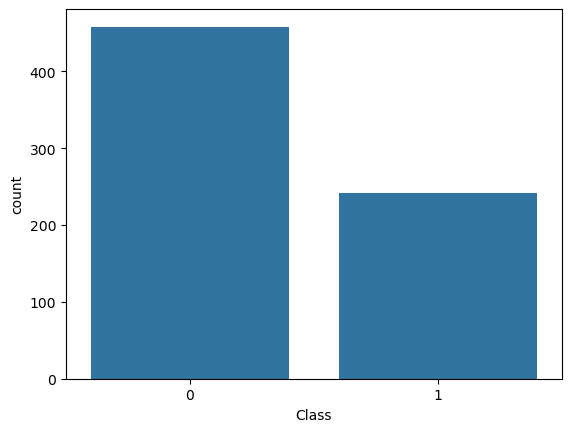

In [19]:
# Target Column
sns.countplot(x='Class',data=data)
plt.show()

In [20]:
data.head()

,Id,Cl.thickness,Cell.size,Cell.shape,Marg.adhesion,Epith.c.size,Bare.nuclei,Bl.cromatin,Normal.nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1.0,3,1,1,0
1,1002945,5,4,4,5,7,10.0,3,2,1,0
2,1015425,3,1,1,1,2,2.0,3,1,1,0
3,1016277,6,8,8,1,3,4.0,3,7,1,0
4,1017023,4,1,1,3,2,1.0,3,1,1,0


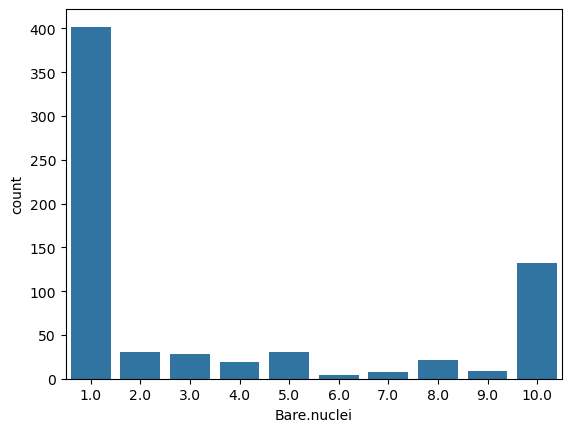

In [21]:
# Analyzing Bare.nuclei
sns.countplot(x='Bare.nuclei',data=data)
plt.show()

#SUBPLOT
plt.figure(figsize=(20,25),facecolor='pink')
plotnumber=1

for column in data:
    if plotnumber<=9:
        ax=plt.subplot(3,3,plotnumber)
        sns.histplot(data[column])
        plt.xlabel(column,fontsize=20)
        plt.ylabel('Count',fontsize=20)
    plotnumber+=1
plt.tight_layout()

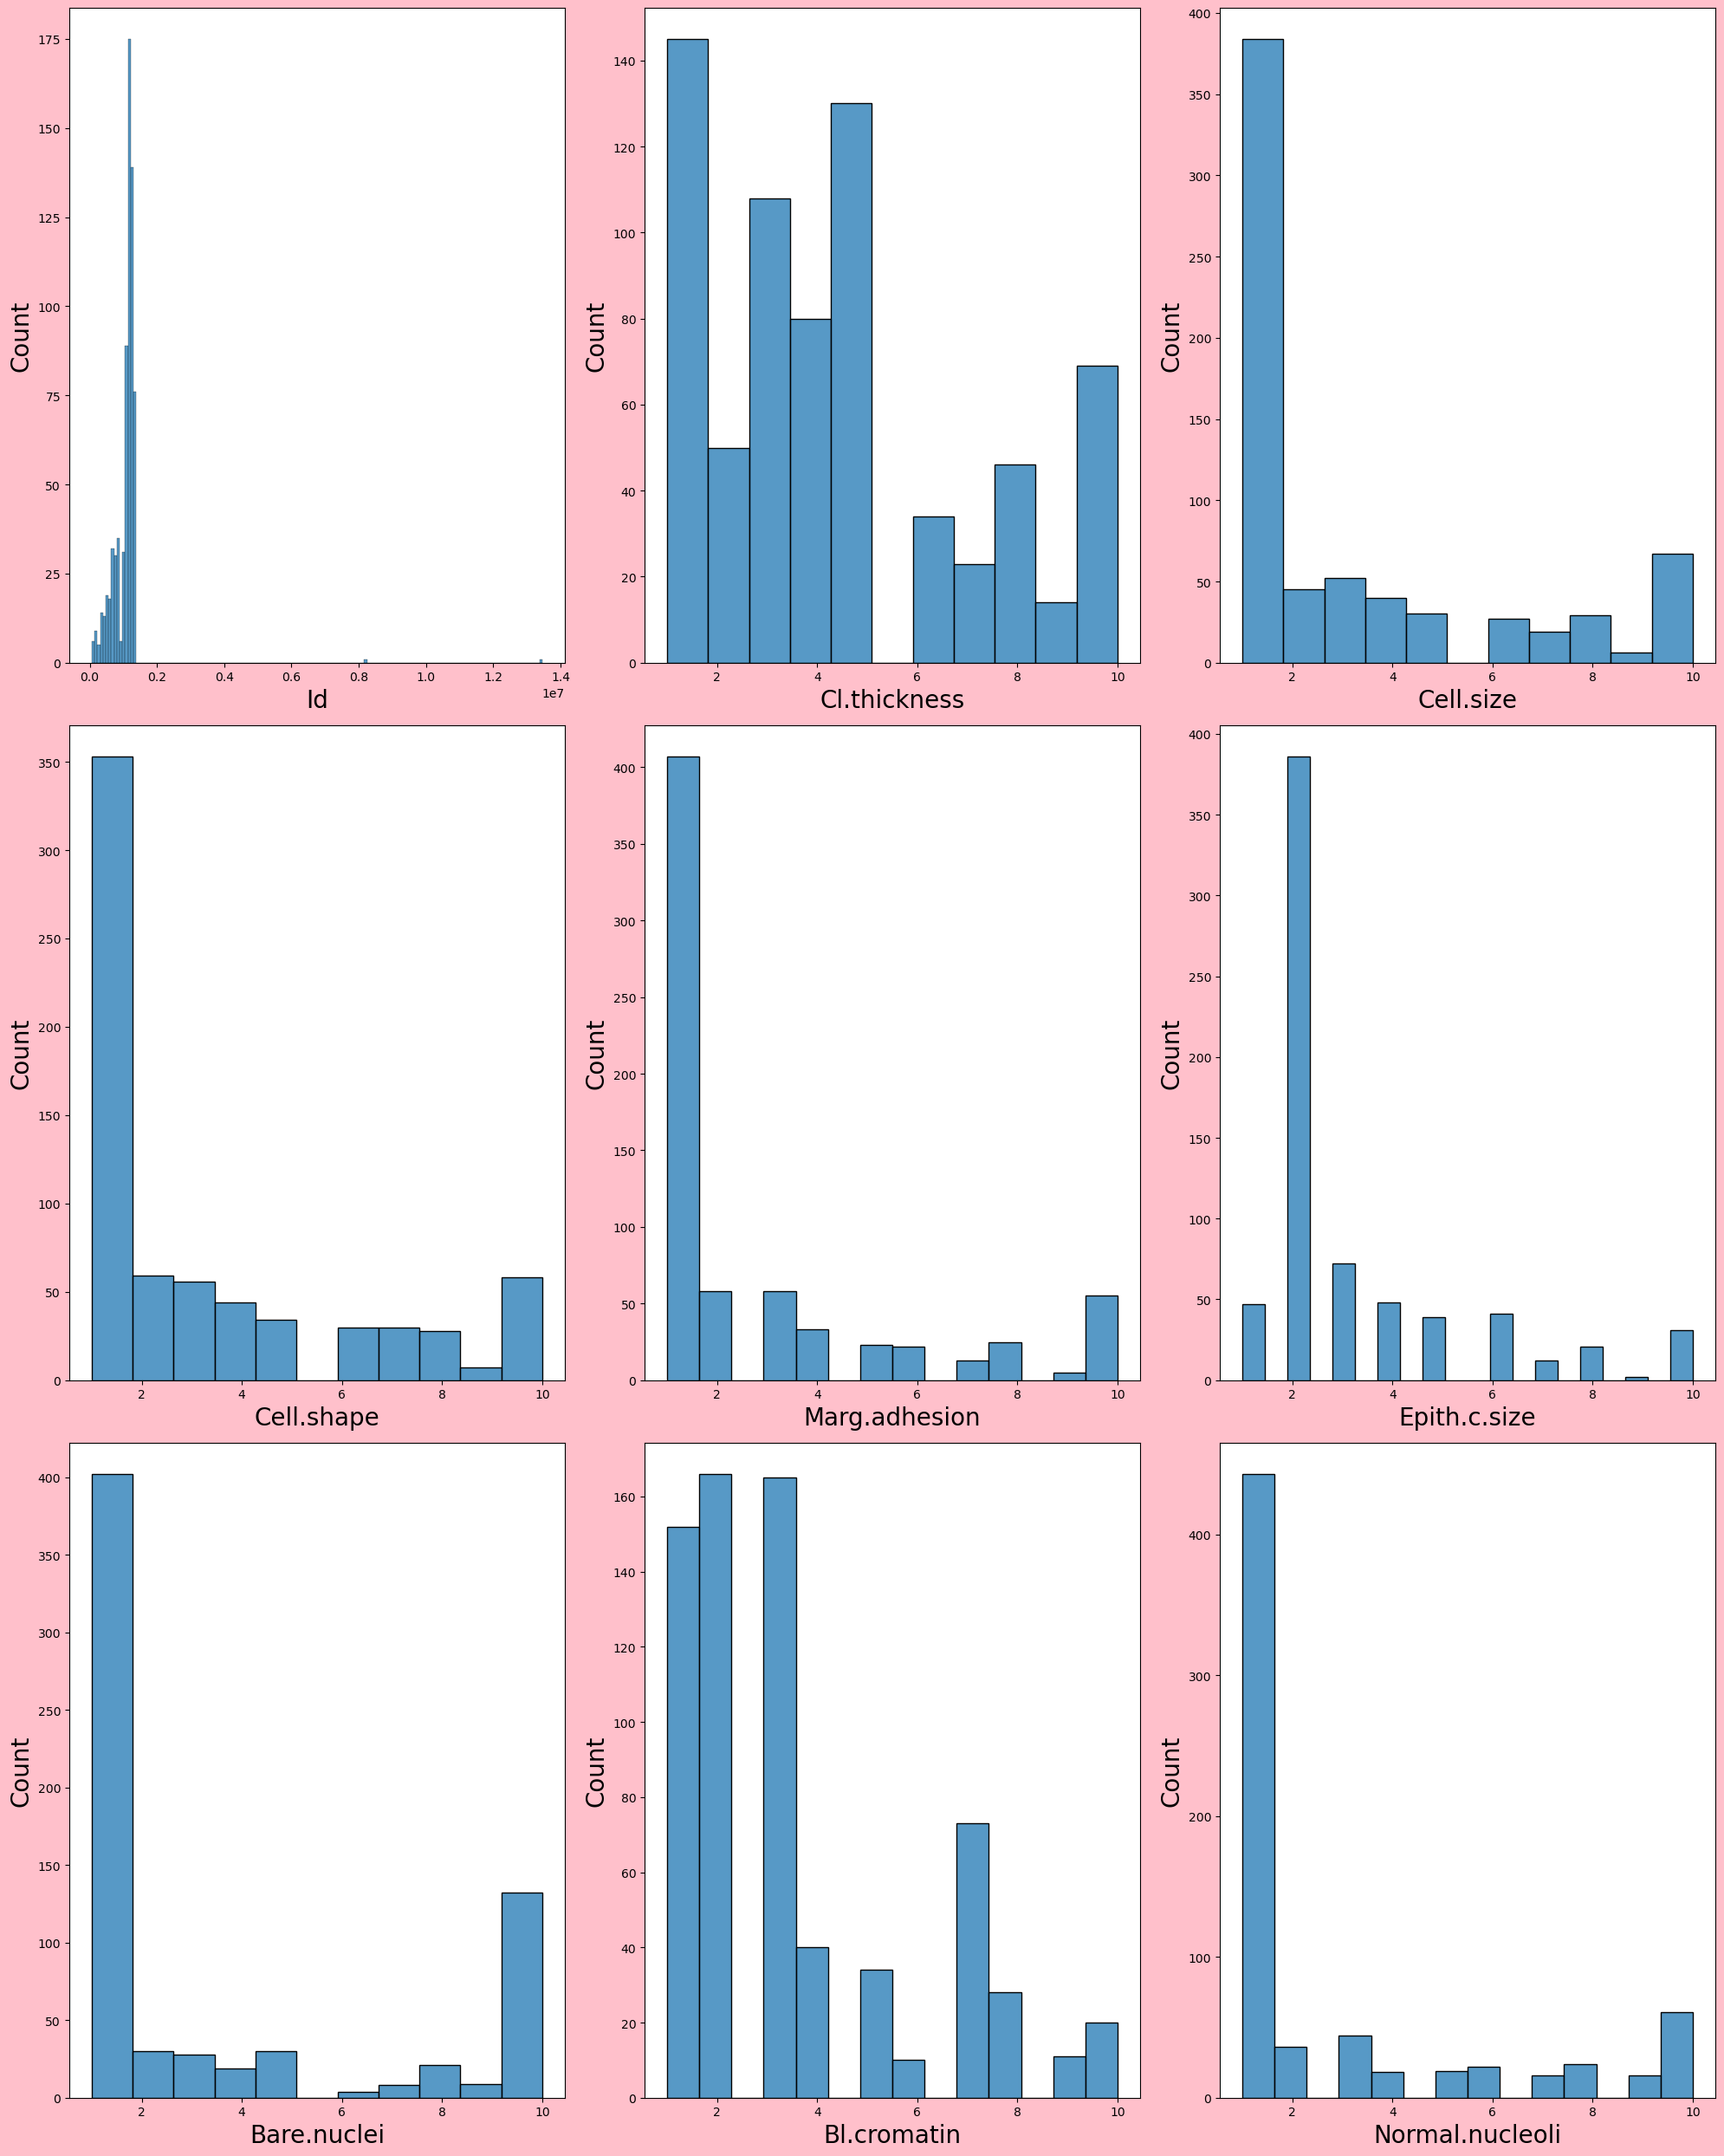

In [22]:
#SUBPLOT
plt.figure(figsize=(20,25),facecolor='pink')
plotnumber=1

for column in data:
    if plotnumber<=9:
        ax=plt.subplot(3,3,plotnumber)
        sns.histplot(data[column])
        plt.xlabel(column,fontsize=20)
        plt.ylabel('Count',fontsize=20)
    plotnumber+=1
plt.tight_layout()

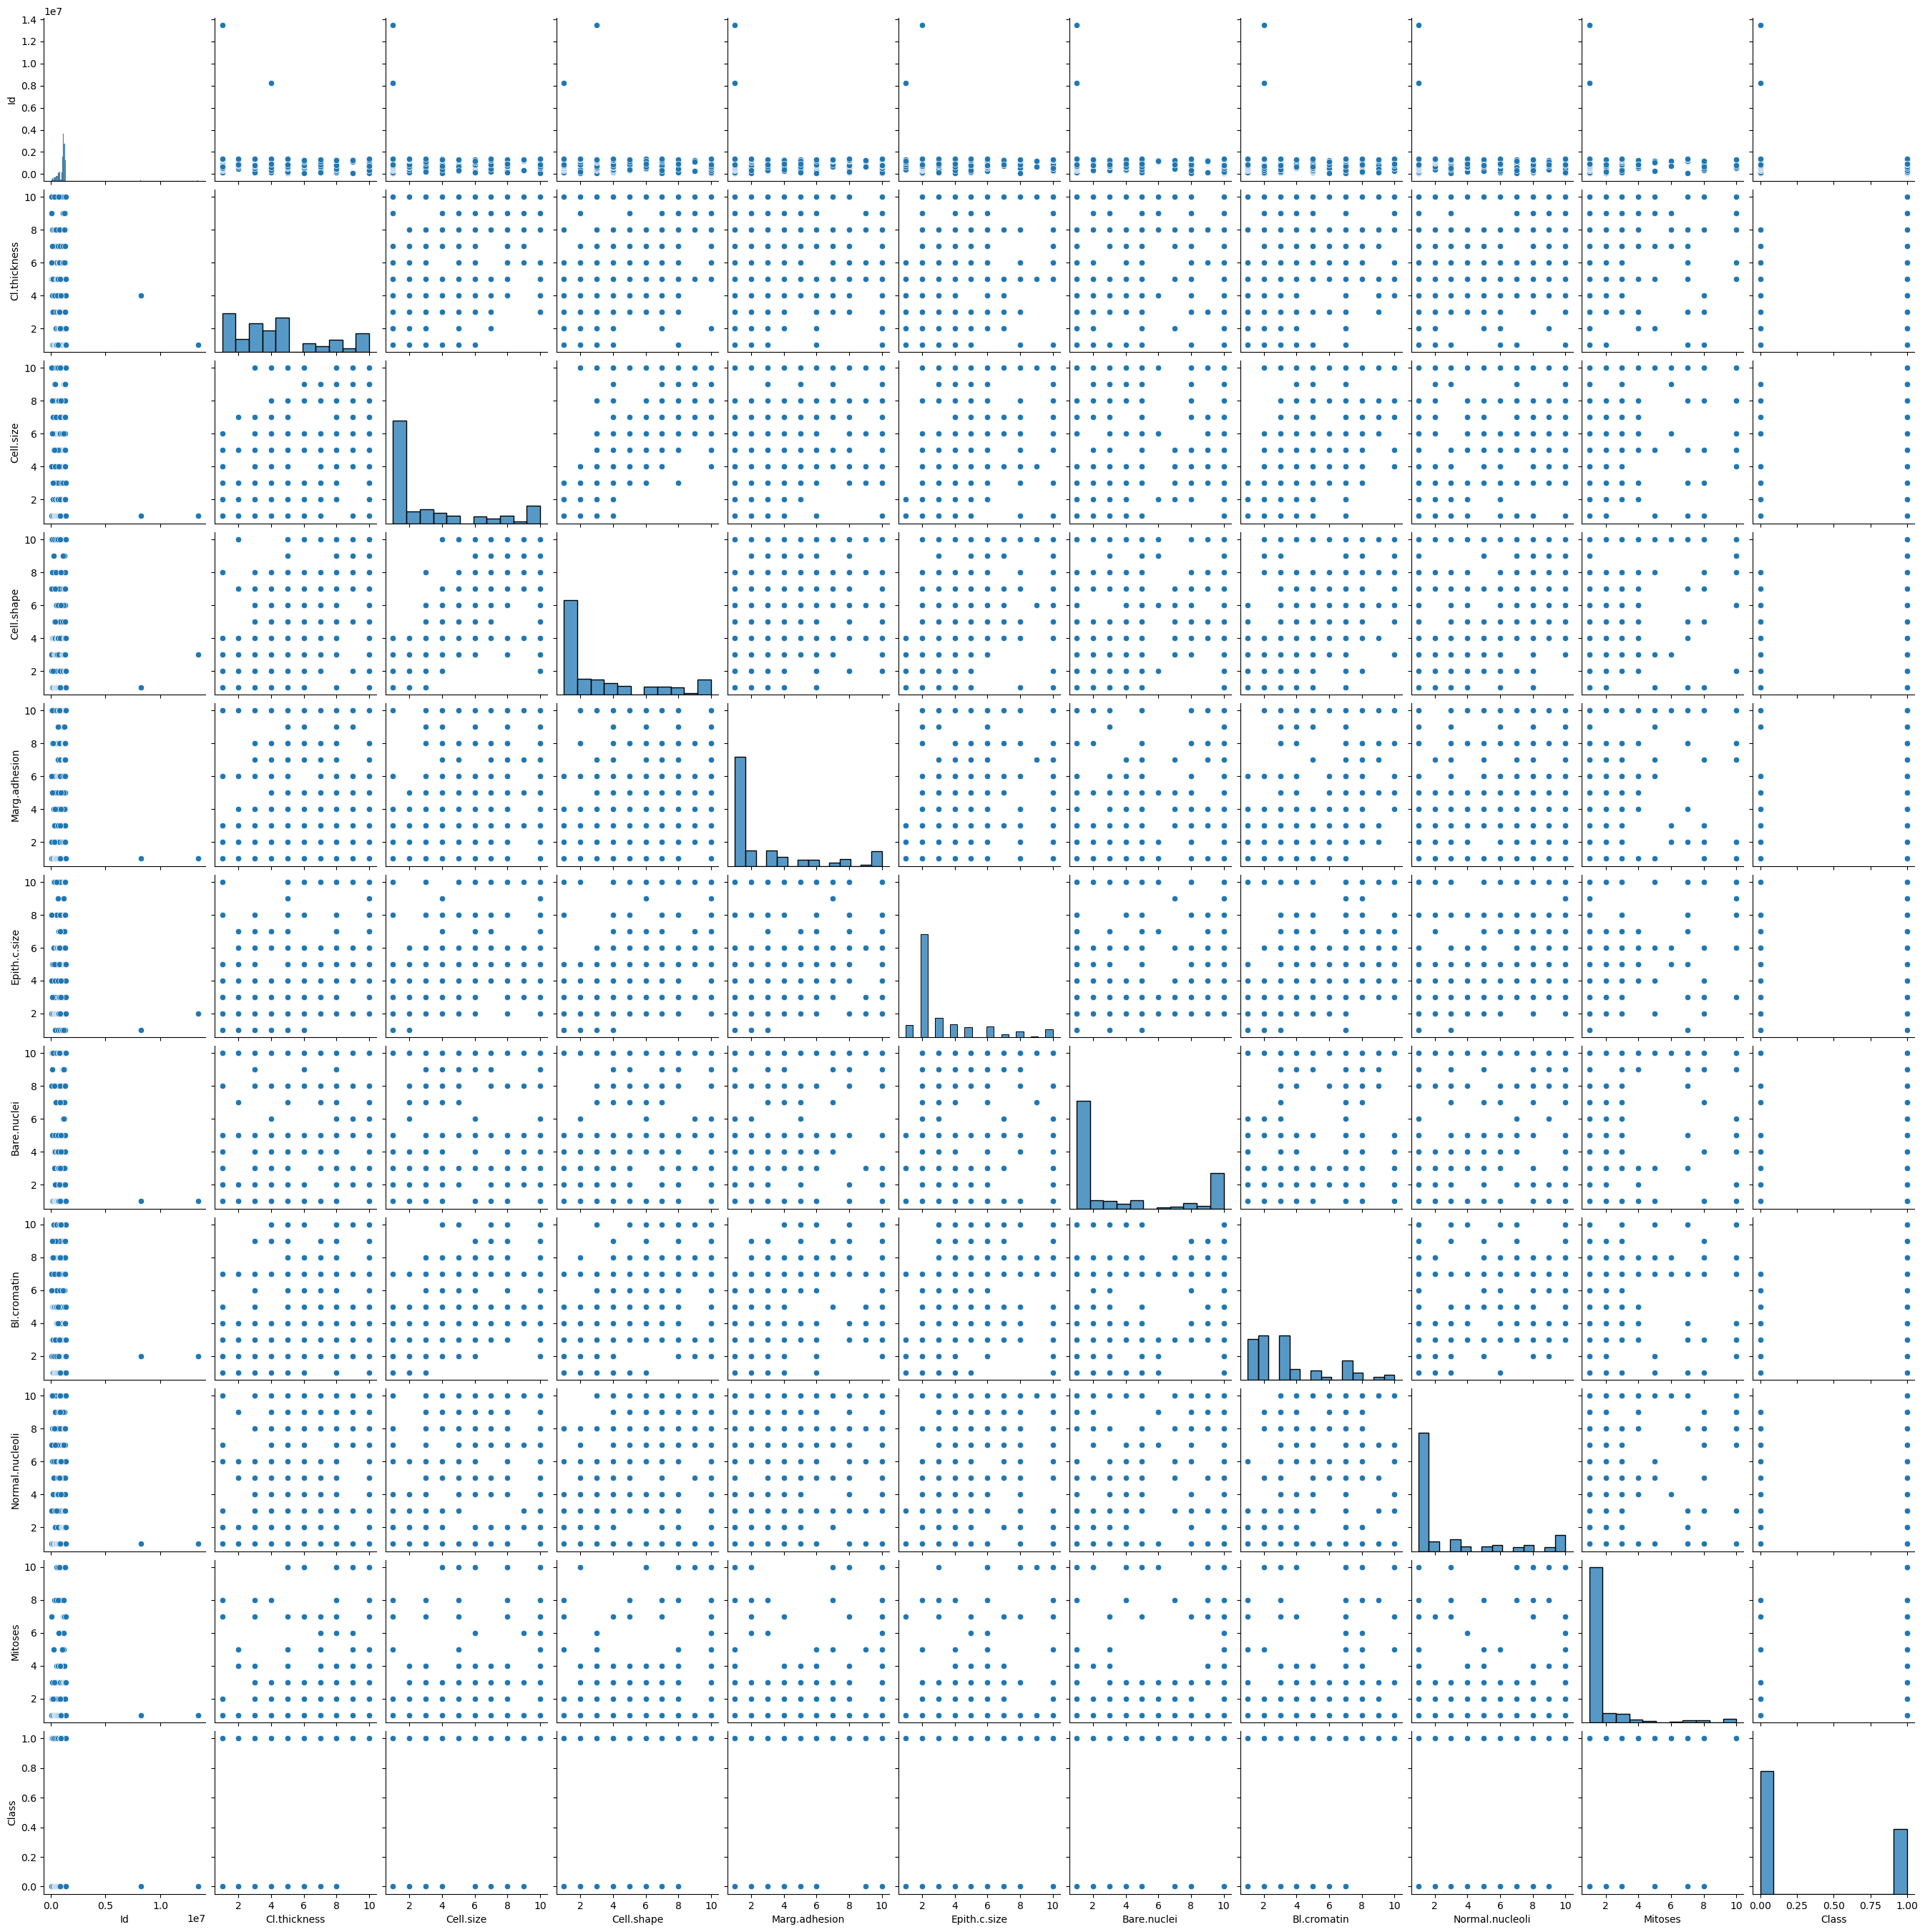

In [23]:
sns.pairplot(data)
plt.show()

In [24]:
#Bivariate

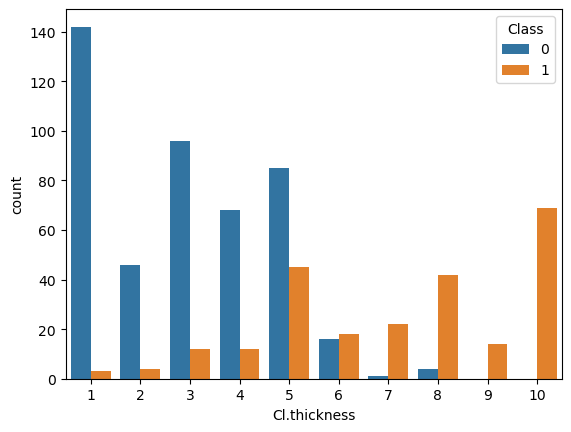

In [26]:
#Analyzing Cl.thickness vs Class
sns.countplot(x='Cl.thickness',data=data,hue='Class')
plt.show()

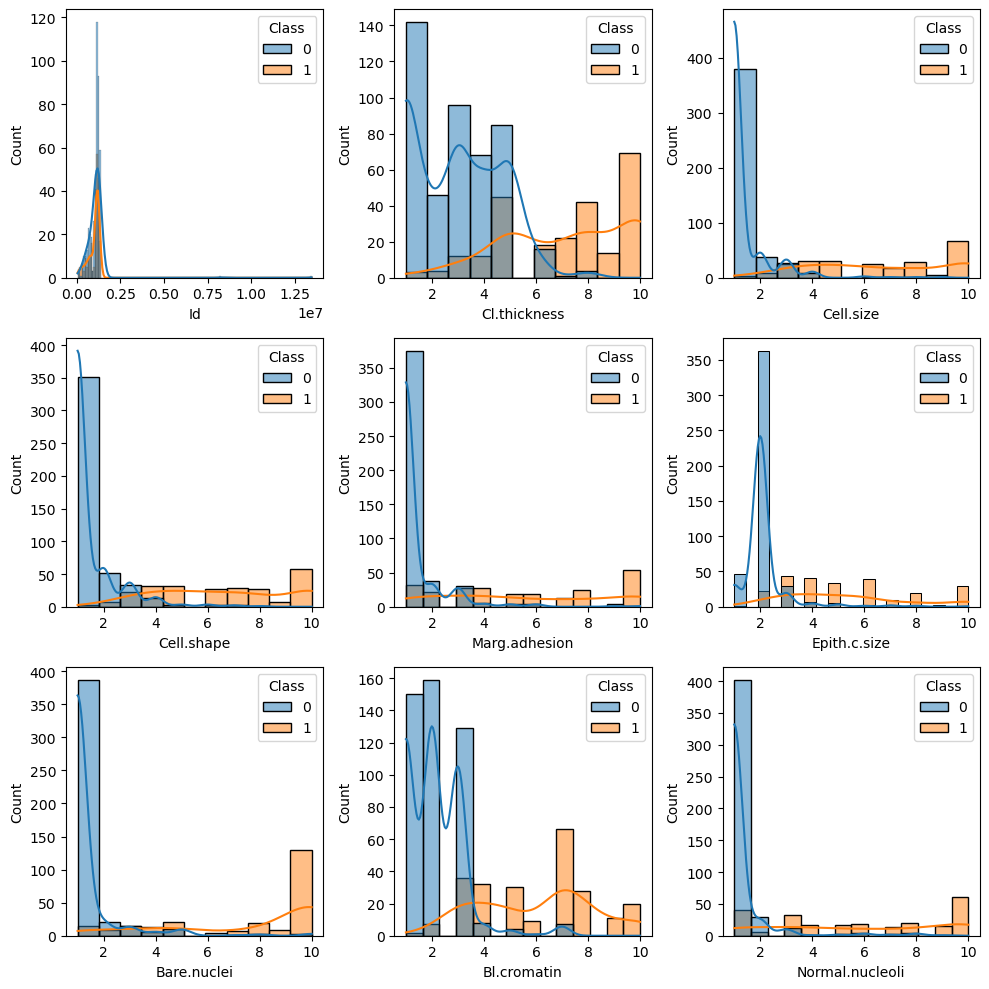

In [27]:
#SUBPLOT - input vs target
plt.figure(figsize=(10,10))
plotnumber =1

for i in data.drop('Class',axis=1):
    if plotnumber <= 9:
        ax = plt.subplot(3,3,plotnumber)
        sns.histplot(x=data[i], hue=data['Class'],kde=True)
        plt.xlabel(i,fontsize=10)
    plotnumber +=1
plt.tight_layout()

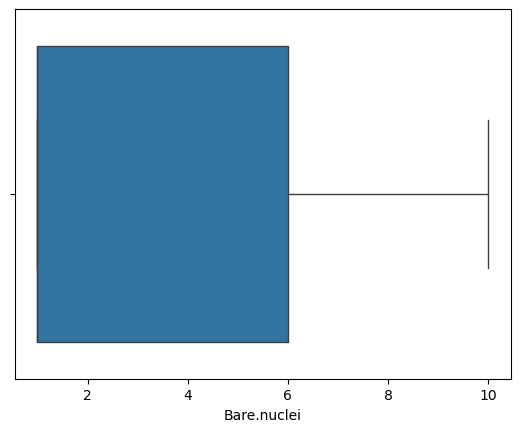

In [29]:
sns.boxplot(x='Bare.nuclei',data=data)
plt.show()

## Preprocessing

In [28]:
data.isnull().sum()

Id                  0
Cl.thickness        0
Cell.size           0
Cell.shape          0
Marg.adhesion       0
Epith.c.size        0
Bare.nuclei        16
Bl.cromatin         0
Normal.nucleoli     0
Mitoses             0
Class               0
dtype: int64

In [31]:
data['Bare.nuclei'] = data['Bare.nuclei'].fillna(data['Bare.nuclei'].mean())

In [32]:
data.isnull().sum()

Id                 0
Cl.thickness       0
Cell.size          0
Cell.shape         0
Marg.adhesion      0
Epith.c.size       0
Bare.nuclei        0
Bl.cromatin        0
Normal.nucleoli    0
Mitoses            0
Class              0
dtype: int64

In [34]:
data.duplicated().sum()

np.int64(8)

In [35]:
data.drop_duplicates(inplace=True)

In [36]:
data.duplicated().sum()

np.int64(0)

In [37]:
data.columns

Index(['Id', 'Cl.thickness', 'Cell.size', 'Cell.shape', 'Marg.adhesion',
       'Epith.c.size', 'Bare.nuclei', 'Bl.cromatin', 'Normal.nucleoli',
       'Mitoses', 'Class'],
      dtype='object')

In [41]:
data.Class.value_counts()

Class
0    453
1    238
Name: count, dtype: int64

## Feature Engineering

In [46]:
from imblearn.over_sampling import SMOTE
sm = SMOTE(random_state=42)
X_balanced, y_balanced = sm.fit_resample(X, y)
print("Before:", y.value_counts())
print("After:", y_balanced.value_counts())

NameError: name 'X' is not defined

In [38]:
#outlier detection
  # handling outlier is very important for the logostic model
# plot a box plot and then decide whether a column has a outlier or not


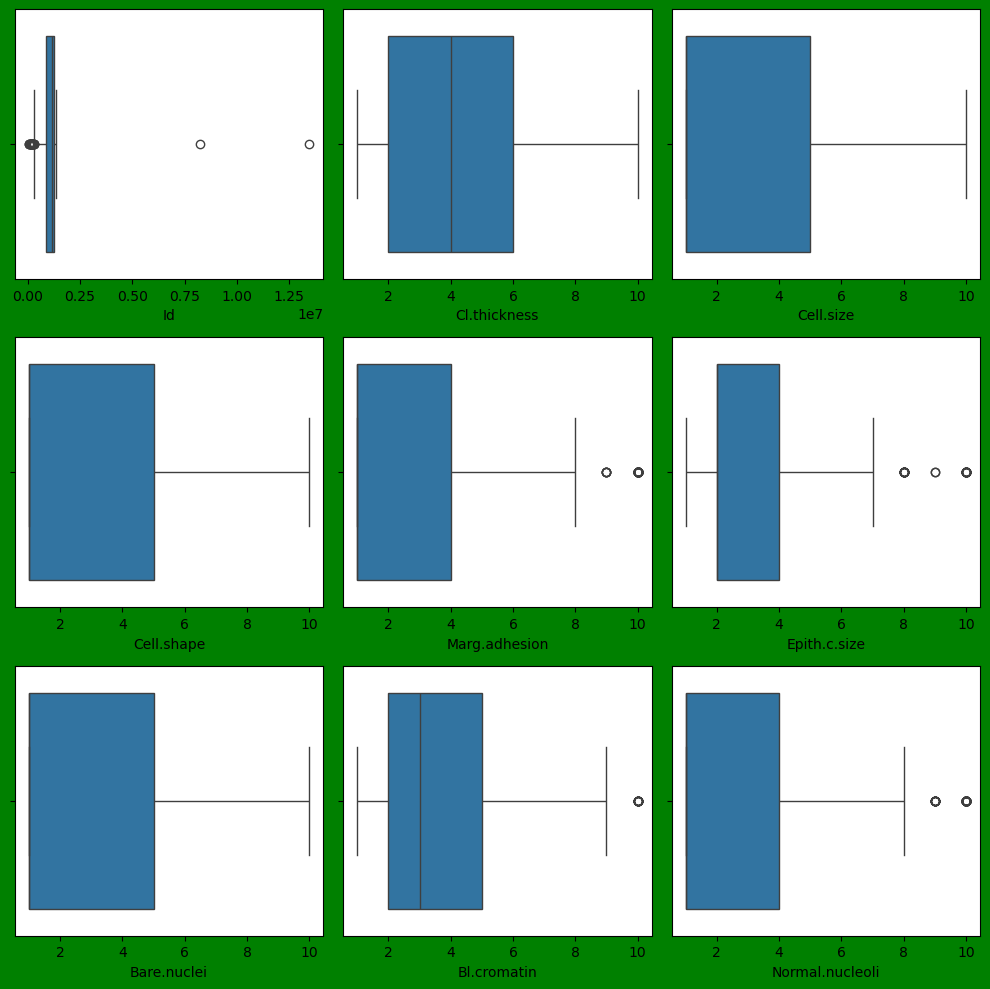

In [39]:
# SUBPLOT
plt.figure(figsize=(10,10),facecolor="green")
plotnumber =1

for i in data.drop('Class',axis=1):
    if plotnumber <=9:
        ax = plt.subplot(3,3,plotnumber)
        sns.boxplot(x=data[i])
        plt.xlabel(i,fontsize=10)
    plotnumber +=1
plt.tight_layout()

<Axes: >

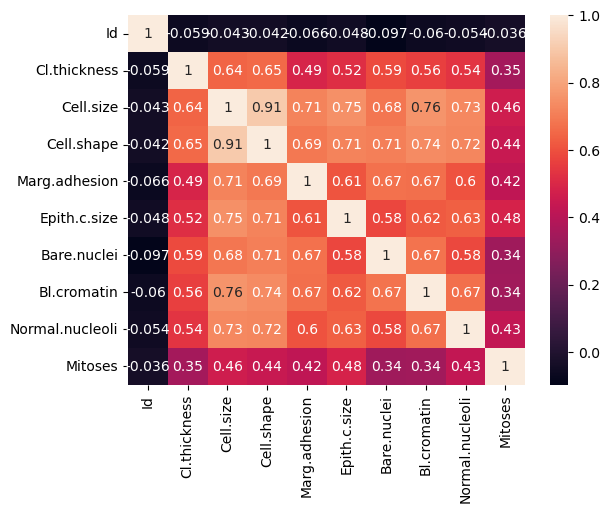

In [40]:
sns.heatmap(data.drop('Class',axis=1).corr(),annot=True)

## Model Building

In [48]:
X = data.drop('Class', axis=1)
y = data['Class']

In [49]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [50]:
from imblearn.over_sampling import SMOTE
sm = SMOTE(random_state=42)
X_balanced, y_balanced = sm.fit_resample(X, y)
print("Before:", y.value_counts())
print("After:", y_balanced.value_counts())

Before: Class
0    453
1    238
Name: count, dtype: int64
After: Class
0    453
1    453
Name: count, dtype: int64


In [51]:
# 4. Scale 
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)


In [52]:
print(" Scaling successful!")
print("X_train shape:", X_train_sc.shape)
print("X_test shape :", X_test_sc.shape)

 Scaling successful!
X_train shape: (552, 10)
X_test shape : (139, 10)


In [55]:
lr = LogisticRegression(max_iter=20, random_state=42)
lr.fit(X_train_sc, y_train)

LogisticRegression(max_iter=20, random_state=42)

In [56]:
y_pred_lr = lr.predict(X_test_sc)

In [69]:
y_prob = lr.predict_proba(X_test_sc)[:, 1]
y_pred_lr = (y_prob >= 0.3).astype(int)  # lower from 0.5 → 0.3

In [70]:
y_pred_lr

array([0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1,
       0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0,
       1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 1])

## Model Evaluation

In [71]:
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score,f1_score, recall_score, roc_auc_score, roc_curve)

In [72]:
print(f"Accuracy Score : {accuracy_score(y_test, y_pred_lr):.4f}")

Accuracy Score : 0.9712


In [73]:
print(f"Precision Score : {precision_score(y_test, y_pred_lr):.4f}")

Precision Score : 0.9783


In [74]:
print(f"f1 Score : {f1_score(y_test, y_pred_lr):.4f}")

f1 Score : 0.9574


In [75]:
print(f"recall Score : {recall_score(y_test, y_pred_lr):.4f}")

recall Score : 0.9375


In [76]:
print(f"ROC-AUC Score : {roc_auc_score(y_test, lr.predict_proba(X_test_sc)[:,1]):.4f}")

ROC-AUC Score : 0.9970


In [77]:
print(confusion_matrix(y_test, y_pred_lr))

[[90  1]
 [ 3 45]]


In [62]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.96      0.99      0.97        91
           1       0.98      0.92      0.95        48

    accuracy                           0.96       139
   macro avg       0.97      0.95      0.96       139
weighted avg       0.96      0.96      0.96       139



In [79]:
import pickle

# Save model
with open('breast_cancer_model.pkl', 'wb') as f:
    pickle.dump(lr, f)

# Save scaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print(" Model saved!")

 Model saved!


In [80]:
import os
print(os.getcwd())   # prints current working directory

C:\Users\ADMIN\OneDrive\Desktop\Data Science\Module  7 Machine Learning Associate\MLA-5 Logistic Regression


In [1]:
pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.
